# Multi-Robot Patrolling — 20% edge removal — Look-Ahead + Rollout Policy (5-Step)

Two robots on a 10x10 grid. Baseline is coordinated Highest-Idleness-First (HIF); the alternative is a look-ahead rollout policy that enumerates 5-step joint paths, scores each with MAX(neural-network prediction on the final state, every instantaneous step value along the path), and executes only the first step of the lowest-cost path.

Part of a matched set of six notebooks (0% / 20% removal x 2 / 3 / 5 step) in which **every setting except lookahead depth and topology is identical**.

## Standardised settings

| Setting | Value |
|---|---|
| `N_STEPS` (main rollout) | 5000 |
| Reporting window | last 1000 steps |
| `N_ABLATION_STEPS` | 5000 |
| Diagnostic | **merged into the main rollout** — same 5000-step run, same last-1000 window |
| Split seeds | `random_state=1`, then `2` |
| `torch.manual_seed` | 0 |
| Graph seed | 123 |

## Changes in this revision

**1. The diagnostic is merged into the main rollout.** Previously the reachability diagnostic ran its own short simulation (1000 steps, first 500 discarded). That turned out to measure a *different regime* than the performance numbers: on the 10% graph at 3-step, the separate diagnostic reported mean MaxIdle 748 while the main rollout on the same policy reported 262 — nearly 3x apart, because the 1000-step diagnostic window sat inside a transient that ran to roughly step 1300. The main rollout already simulates 5000 steps and already tracks MaxIdle, so distance-to-worst-node tracking has simply been added to it. The diagnostic now reports over the identical last-1000 window as the performance table, is directly comparable to it, and costs **nothing extra**.

**2. Candidate evaluation is vectorised (~3.5x faster end-to-end at depth 5).** The per-candidate Python loop has been replaced with an array implementation resting on two identities:

- `idle_k[node] = k - eff_k[node]`, where `eff_k[node]` is the node's last-visit step within the look-ahead, or `-idle0[node]` if never visited. Final idleness is therefore a broadcast fill plus at most `2 x 5` scatter writes.
- Visited nodes satisfy `eff >= 1 > 0 >= -idle0`, so the **maximum** idleness always sits on a never-visited node. Only the `2 x 5 + 1` largest initial-idleness nodes can hold it, which shrinks the per-step max from 100 nodes to 11.

Section 11 contains a self-check that runs both implementations on this notebook's actual graph and asserts they agree exactly. It runs in seconds; if it ever fails, stop and do not trust the rollout.

**3. Explicit collapse detection.** When the policy permanently abandons a node, MaxIdle climbs linearly forever and the reported mean over the last 1000 steps is not a measurement at all — it is exactly `N_STEPS - 499.5`, i.e. **4500.5** at N_STEPS=5000. That is the origin of the recurring 4500.5 in earlier reports, and of 3300.5 (N=3800), 500.5 (N=1000) and 150.5 (N=300). Every rollout is checked and flagged, so a collapsed run is never silently reported as performance.

## On reproducibility vs reliability

`torch.manual_seed(0)` makes this notebook reproducible and makes all six notebooks train from the same initialisation. It does **not** make results reliable. Runs of these notebooks have flipped qualitative conclusions purely from model initialisation — a full-grid 2-step reward=max run that previously looked healthy at MaxIdle 604 later collapsed outright, while a 10% 2-step configuration that previously collapsed on both reward variants later came out healthy on both. Test R2 barely moved in either case. **Offline accuracy does not certify rollout behaviour.** To probe reliability, change `TORCH_SEED` and re-run several times.


## 1. Simulator classes

In [27]:
import numpy as np

def build_grid_graph(rows, cols):
    """Full 4-neighbour grid graph."""
    n_nodes = rows * cols
    neighbors = [[] for _ in range(n_nodes)]
    for i in range(rows):
        for j in range(cols):
            k = i * cols + j
            if i > 0: neighbors[k].append((i - 1) * cols + j)
            if i < rows - 1: neighbors[k].append((i + 1) * cols + j)
            if j > 0: neighbors[k].append(i * cols + (j - 1))
            if j < cols - 1: neighbors[k].append(i * cols + (j + 1))
    return neighbors

class Robot:
    def __init__(self, initial_position, rng):
        self.position = initial_position
        self.rng = rng

    def choose_next(self, neighbors, idleness, forbidden=None):
        current = neighbors[self.position]
        if forbidden is not None:
            filtered = [n for n in current if n != forbidden]
            if filtered:
                current = filtered
        if len(current) == 0:
            return self.position
        nbrs = np.array(current)
        vals = idleness[nbrs]
        return int(self.rng.choice(nbrs[vals == vals.max()]))

class CoordinatedHIFSimulator:
    def __init__(self, seed=42, idleness_init=None, robot1_pos=0, robot2_pos=99,
                 neighbors_override=None):
        self.rng = np.random.default_rng(seed)
        self.rows, self.cols = 10, 10
        self.n_nodes = 100
        self.neighbors = (neighbors_override if neighbors_override is not None
                          else build_grid_graph(self.rows, self.cols))
        self.idleness = (np.zeros(self.n_nodes, dtype=np.int32)
                         if idleness_init is None else idleness_init.copy())
        self.robot1 = Robot(robot1_pos, self.rng)
        self.robot2 = Robot(robot2_pos, self.rng)

    def step(self):
        self.idleness += 1
        n1 = self.robot1.choose_next(self.neighbors, self.idleness)
        n2 = self.robot2.choose_next(self.neighbors, self.idleness, forbidden=n1)
        self.robot1.position, self.robot2.position = n1, n2
        self.idleness[n1] = 0
        self.idleness[n2] = 0
        return self.idleness.mean(), self.idleness.max()

print("Simulator classes defined.")

Simulator classes defined.


## 2. Build the 20% edge-removed graph

**Connectivity-only constraint** (Prof. Sinha, Jul 16): the graph must stay fully connected. A node may be left with a single edge; connectivity is verified directly by traversal after each candidate removal rather than assumed from a minimum-degree rule. Graph seed 123, identical across all three depths.

In [28]:
def build_full_edge_list(rows, cols):
    edges = []
    for i in range(rows):
        for j in range(cols):
            node = i * cols + j
            if j < cols - 1: edges.append((node, node + 1))
            if i < rows - 1: edges.append((node, node + cols))
    return edges

def is_connected(adj, n_nodes):
    visited = [False] * n_nodes
    stack = [0]; visited[0] = True; count = 1
    while stack:
        u = stack.pop()
        for v in adj[u]:
            if not visited[v]:
                visited[v] = True; count += 1; stack.append(v)
    return count == n_nodes

def build_grid_graph_with_removal(rows, cols, removal_fraction, seed=0):
    n_nodes = rows * cols
    edges = build_full_edge_list(rows, cols)
    rng = np.random.default_rng(seed)
    order = rng.permutation(len(edges))
    adj = [set() for _ in range(n_nodes)]
    for a, b in edges:
        adj[a].add(b); adj[b].add(a)
    target = int(round(removal_fraction * len(edges)))
    removed = 0
    for idx in order:
        if removed >= target: break
        a, b = edges[idx]
        adj[a].discard(b); adj[b].discard(a)
        if not is_connected(adj, n_nodes):
            adj[a].add(b); adj[b].add(a); continue
        removed += 1
    print(f"Removed {removed}/{target} edges (of {len(edges)} total) — full connectivity preserved")
    return [sorted(adj[i]) for i in range(n_nodes)]

GRAPH_SEED = 123
REMOVAL_FRACTION = 0.2
REDUCED_NEIGHBORS = build_grid_graph_with_removal(10, 10, removal_fraction=REMOVAL_FRACTION, seed=GRAPH_SEED)

degrees = [len(REDUCED_NEIGHBORS[i]) for i in range(100)]
print("Min degree:", min(degrees), "| Max degree:", max(degrees))
print("Fully connected:", is_connected([set(n) for n in REDUCED_NEIGHBORS], 100))
print("Degree-1 nodes (dead ends):", [i for i, d in enumerate(degrees) if d == 1])

Removed 36/36 edges (of 180 total) — full connectivity preserved
Min degree: 1 | Max degree: 4
Fully connected: True
Degree-1 nodes (dead ends): [0, 9, 45, 50, 94, 99]


## 3. Load the 10,000-run dataset

**On the `.zip` extension:** `np.load` identifies an npz archive by its magic bytes rather than its filename, so a correctly formed archive loads fine even when named `.zip`.

In [29]:
import os

DATASET_PATH = r"D:\Plaksha college\iit bombay  intern\Final run\full_10000run_20pct_dataset.zip"

if not os.path.exists(DATASET_PATH):
    raise FileNotFoundError(f"Dataset not found at:\n  {DATASET_PATH}")

d = np.load(DATASET_PATH)
keys = list(d.keys())
print("Archive loaded. Keys:", keys)
if "X_data" not in keys or "Y_data" not in keys:
    raise KeyError(
        f"Expected 'X_data' and 'Y_data' but found {keys}. If that looks like a single "
        ".npz filename, the file is a zip wrapped around an npz — extract once and repoint."
    )
X_data = d["X_data"]; Y_data = d["Y_data"]
print("X_data:", X_data.shape, "Y_data:", Y_data.shape)
assert X_data.shape[1] == 300 and Y_data.shape[1] == 2

Archive loaded. Keys: ['X_data', 'Y_data']
X_data: (10000, 300) Y_data: (10000, 2)


## 4. Train / validation / test split

In [30]:
from sklearn.model_selection import train_test_split

X_train, X_temp, Y_train, Y_temp = train_test_split(X_data, Y_data, test_size=0.2, random_state=1)
X_val, X_test, Y_val, Y_test = train_test_split(X_temp, Y_temp, test_size=0.5, random_state=2)
print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)

Train: (8000, 300) Val: (1000, 300) Test: (1000, 300)


## 5. Normalization

Plain z-score only — no `log1p` / `expm1`, which previously caused predictions to explode on unfamiliar inputs.

In [31]:
mean = X_train[:, :100].mean(axis=0)
std = X_train[:, :100].std(axis=0)
std[std < 1e-6] = 1.0
X_train[:, :100] = (X_train[:, :100] - mean) / std
X_val[:, :100]   = (X_val[:, :100]   - mean) / std
X_test[:, :100]  = (X_test[:, :100]  - mean) / std

y_mean = Y_train.mean(axis=0)
y_std = Y_train.std(axis=0)
y_std[y_std < 1e-6] = 1.0
Y_train_n = (Y_train - y_mean) / y_std
Y_val_n   = (Y_val   - y_mean) / y_std
Y_test_n  = (Y_test  - y_mean) / y_std

print("Normalization complete (no log1p/expm1).")
print("y_mean:", y_mean, "| y_std:", y_std)

Normalization complete (no log1p/expm1).
y_mean: [32.65933  88.315125] | y_std: [ 7.690295 66.95095 ]


## 6. Model architecture (300 -> 128 -> 64 -> 2)

In [32]:
import torch
import torch.nn as nn

class PatrollingMLP(nn.Module):
    def __init__(self, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(300, 128), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(128, 64), nn.ReLU(), nn.Dropout(dropout),
            nn.Linear(64, 2)
        )
    def forward(self, x):
        return self.net(x)

print("PatrollingMLP defined (128 -> 64).")

PatrollingMLP defined (128 -> 64).


## 7. Training

`torch.manual_seed(0)` fixed before model construction.

Device: cpu | torch seed: 0
Epoch 001/100 | LR 0.000500 | Train 0.305279 | Val 0.274827
Epoch 002/100 | LR 0.000500 | Train 0.231718 | Val 0.177704
Epoch 003/100 | LR 0.000500 | Train 0.140363 | Val 0.122678
Epoch 004/100 | LR 0.000500 | Train 0.114262 | Val 0.112040
Epoch 005/100 | LR 0.000500 | Train 0.103408 | Val 0.106514
Epoch 006/100 | LR 0.000500 | Train 0.095079 | Val 0.101889
Epoch 007/100 | LR 0.000500 | Train 0.090017 | Val 0.100633
Epoch 008/100 | LR 0.000500 | Train 0.084291 | Val 0.095979
Epoch 009/100 | LR 0.000500 | Train 0.079140 | Val 0.094108
Epoch 010/100 | LR 0.000500 | Train 0.074200 | Val 0.093082
Epoch 011/100 | LR 0.000500 | Train 0.069133 | Val 0.089972
Epoch 012/100 | LR 0.000500 | Train 0.065077 | Val 0.090042
Epoch 013/100 | LR 0.000500 | Train 0.059419 | Val 0.084704
Epoch 014/100 | LR 0.000500 | Train 0.053492 | Val 0.082879
Epoch 015/100 | LR 0.000500 | Train 0.050464 | Val 0.080290
Epoch 016/100 | LR 0.000500 | Train 0.046792 | Val 0.079762
Epoch 017/10

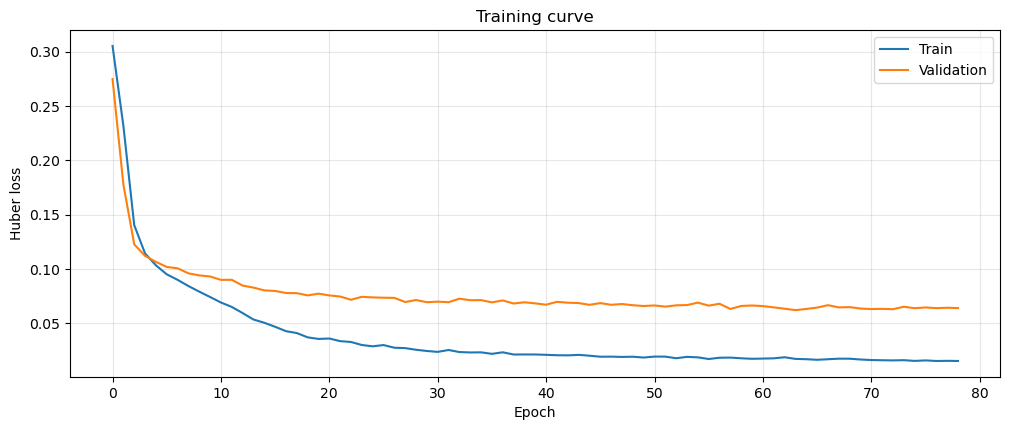

In [33]:
import matplotlib.pyplot as plt
from torch.utils.data import Dataset, DataLoader

TORCH_SEED = 0
torch.manual_seed(TORCH_SEED)
np.random.seed(TORCH_SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE, "| torch seed:", TORCH_SEED)

class PatrollingDataset(Dataset):
    def __init__(self, X, Y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.Y = torch.tensor(Y, dtype=torch.float32)
    def __len__(self): return len(self.X)
    def __getitem__(self, i): return self.X[i], self.Y[i]

train_loader = DataLoader(PatrollingDataset(X_train, Y_train_n), batch_size=256, shuffle=True)
val_loader   = DataLoader(PatrollingDataset(X_val,   Y_val_n),   batch_size=256, shuffle=False)
test_loader  = DataLoader(PatrollingDataset(X_test,  Y_test_n),  batch_size=256, shuffle=False)

model = PatrollingMLP(dropout=0.2).to(DEVICE)
criterion = nn.HuberLoss(delta=1.0)
optimizer = torch.optim.Adam(model.parameters(), lr=5e-4, weight_decay=1e-5)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=0.5, patience=5)

EPOCHS, PATIENCE = 100, 15
best_val, wait = float("inf"), 0
train_losses, val_losses = [], []
CKPT = "best_model_20pct_5step.pt"

for epoch in range(EPOCHS):
    model.train(); running = 0.0
    for Xb, yb in train_loader:
        Xb, yb = Xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(model(Xb), yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        running += loss.item() * Xb.size(0)
    tr = running / len(train_loader.dataset)

    model.eval(); running = 0.0
    with torch.no_grad():
        for Xb, yb in val_loader:
            Xb, yb = Xb.to(DEVICE), yb.to(DEVICE)
            running += criterion(model(Xb), yb).item() * Xb.size(0)
    va = running / len(val_loader.dataset)
    scheduler.step(va)
    train_losses.append(tr); val_losses.append(va)
    print(f"Epoch {epoch+1:03d}/{EPOCHS} | LR {optimizer.param_groups[0]['lr']:.6f} | Train {tr:.6f} | Val {va:.6f}")

    if va < best_val:
        best_val, wait = va, 0
        torch.save(model.state_dict(), CKPT)
    else:
        wait += 1
        if wait >= PATIENCE:
            print(f"\nEarly stopping at epoch {epoch+1}"); break

model.load_state_dict(torch.load(CKPT, map_location=DEVICE))
print("\nTraining complete. Best validation loss:", best_val)

plt.figure(figsize=(12,4.5))
plt.plot(train_losses, label="Train"); plt.plot(val_losses, label="Validation")
plt.xlabel("Epoch"); plt.ylabel("Huber loss"); plt.title("Training curve")
plt.legend(); plt.grid(alpha=0.3); plt.show()

## 8. Evaluation

In [34]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

model.eval()
P, T_ = [], []
with torch.no_grad():
    for Xb, yb in test_loader:
        P.append(model(Xb.to(DEVICE)).cpu().numpy()); T_.append(yb.numpy())
preds = np.vstack(P) * y_std + y_mean
targs = np.vstack(T_) * y_std + y_mean

for name, col in (("FUTURE MAX IAI", 0), ("FUTURE MAX MAXIDLE", 1)):
    t, p = targs[:, col], preds[:, col]
    print(f"== {name} ==")
    print(f"MAE  : {mean_absolute_error(t, p):.4f}")
    print(f"RMSE : {np.sqrt(mean_squared_error(t, p)):.4f}")
    print(f"R2   : {r2_score(t, p):.4f}\n")

print("Caution: R2 is not comparable across topologies. Reduced graphs have far wider target")
print("spread, so the same absolute error explains a larger share of variance. Compare MAE/RMSE.")
print("R2 also does not certify rollout behaviour — see the note on reliability in the intro.")

== FUTURE MAX IAI ==
MAE  : 1.1064
RMSE : 2.7251
R2   : 0.8417

== FUTURE MAX MAXIDLE ==
MAE  : 9.0307
RMSE : 24.0769
R2   : 0.8382

Caution: R2 is not comparable across topologies. Reduced graphs have far wider target
spread, so the same absolute error explains a larger share of variance. Compare MAE/RMSE.
R2 also does not certify rollout behaviour — see the note on reliability in the intro.


## 9. Look-ahead machinery — 5-step

`simulate_n_steps_forward` is the original per-candidate reference implementation. It is kept because Section 11 checks the fast vectorised path against it.

In [35]:
idle_mean, idle_std = mean, std

In [36]:
DIRECTIONS = {
    'up':    lambda p: p - 10 if p >= 10 else None,
    'down':  lambda p: p + 10 if p < 90 else None,
    'left':  lambda p: p - 1 if p % 10 != 0 else None,
    'right': lambda p: p + 1 if p % 10 != 9 else None,
}
OPPOSITE = {'up': 'down', 'down': 'up', 'left': 'right', 'right': 'left'}
DIRLIST = ['up', 'down', 'left', 'right']

def get_valid_moves(pos, exclude_dir=None, neighbors=None):
    """
    Legal moves from pos: on-grid, edge present, and not the reverse of exclude_dir.

    DEAD-END FALLBACK: if forbidding the backtrack leaves no legal move (a degree-1 node
    whose only edge is the one just traversed) the backtrack is permitted. Without this the
    candidate list empties and the rollout breaks on reduced graphs.
    """
    def moves_with(exclude):
        out = []
        for dname in DIRLIST:
            if exclude is not None and dname == OPPOSITE[exclude]:
                continue
            q = DIRECTIONS[dname](pos)
            if q is None:
                continue
            if neighbors is not None and q not in neighbors[pos]:
                continue
            out.append((dname, q))
        return out

    moves = moves_with(exclude_dir)
    if not moves and exclude_dir is not None:
        moves = moves_with(None)
    return moves

def enumerate_full_paths(start_pos, n_steps, neighbors):
    seqs, poss = [[]], [start_pos]
    for _ in range(n_steps):
        ns, npos = [], []
        for s, p in zip(seqs, poss):
            last = s[-1] if s else None
            for dname, q in get_valid_moves(p, exclude_dir=last, neighbors=neighbors):
                ns.append(s + [dname]); npos.append(q)
        seqs, poss = ns, npos
    return seqs

def seq_positions(start_pos, seqs, n_steps):
    """(n_seq, n_steps) array of positions visited after each step."""
    out = np.empty((len(seqs), n_steps), dtype=np.int64)
    for i, s in enumerate(seqs):
        p = start_pos
        for k, dname in enumerate(s):
            p = DIRECTIONS[dname](p)
            out[i, k] = p
    return out

def simulate_n_steps_forward(idleness, r1_pos, r2_pos, r1_dirs, r2_dirs):
    """REFERENCE implementation (slow). Used only by the Section 11 equivalence check."""
    idle = idleness.copy()
    p1, p2 = r1_pos, r2_pos
    step_avgs, step_maxs = [], []
    for d1, d2 in zip(r1_dirs, r2_dirs):
        q1 = DIRECTIONS[d1](p1); q2 = DIRECTIONS[d2](p2)
        if q1 is None or q2 is None: return None
        if q1 == q2: return None
        idle = idle + 1; idle[q1] = 0; idle[q2] = 0
        step_avgs.append(idle.mean()); step_maxs.append(idle.max())
        p1, p2 = q1, q2
    return idle, p1, p2, step_avgs, step_maxs

LOOKAHEAD_DEPTH = 5
print(f"Look-ahead machinery defined (depth {LOOKAHEAD_DEPTH}).")

Look-ahead machinery defined (depth 5).


## 10. Vectorised candidate evaluator

Replaces the per-candidate Python loop. Rests on two identities:

1. `idle_k[node] = k - eff_k[node]` where `eff_k[node]` is the node's last-visit step within the look-ahead, or `-idle0[node]` if never visited. Final idleness is therefore a broadcast fill plus at most `2 x 5` scatter writes (ascending `k`, so the last visit wins).
2. Visited nodes have `eff >= 1 > 0 >= -idle0`, so the **maximum** idleness always sits on a never-visited node. At most `2 x 5` nodes are visited, so only the `2 x 5 + 1 = 11` largest initial-idleness nodes can hold the max — reducing the per-step max from 100 nodes to 11.

The mean is tracked incrementally through `sum(eff)`, avoiding a full recomputation each step.

In [37]:
def eval_candidates(idleness, P1, P2, need, n_nodes=100, build_x=True):
    """
    Vectorised evaluation of every joint candidate (row-major: i * len(P2) + j).

    Returns
      valid      : (C,)      no-collision at every intermediate step
      X          : (C, 300)  NN input (final idleness ++ r1 one-hot ++ r2 one-hot),
                             or None when build_x=False
      step_vals  : (C, T)    per-step instantaneous metric ('max' or 'avg')
      f1, f2     : (C,)      final robot positions

    build_x=False skips constructing X entirely. The NO-NN ablation never consults the
    network, so it does not need X — and at depth 5 on the full grid that array is
    ~124 MB per decision, making this by far the largest single cost to avoid.
    """
    A, T = P1.shape
    B = P2.shape[0]
    C = A * B
    p1 = np.repeat(P1, B, axis=0)
    p2 = np.tile(P2, (A, 1))
    valid = np.all(p1 != p2, axis=1)
    rows = np.arange(C)
    idle0 = idleness.astype(np.float32)

    # --- NN input: final idleness = T - eff_T, then one-hots ---
    X = None
    if build_x:
        X = np.zeros((C, 3 * n_nodes), dtype=np.float32)
        X[:, :n_nodes] = idle0 + T                      # never-visited case
        for k in range(1, T + 1):                       # ascending -> last visit wins
            X[rows, p1[:, k - 1]] = T - k
            X[rows, p2[:, k - 1]] = T - k
        X[rows, n_nodes + p1[:, -1]] = 1.0
        X[rows, 2 * n_nodes + p2[:, -1]] = 1.0

    # --- per-step instantaneous metric ---
    step_vals = np.empty((C, T), dtype=np.float32)
    if need == 'max':
        K = 2 * T + 1
        cand_nodes = np.argsort(-idle0)[:K]
        cand_idle0 = idle0[cand_nodes]
        node_to_j = -np.ones(n_nodes, dtype=np.int64)
        node_to_j[cand_nodes] = np.arange(K)
        seen = np.zeros((C, K), dtype=bool)
        for k in range(1, T + 1):
            for q in (p1[:, k - 1], p2[:, k - 1]):
                j = node_to_j[q]; m = j >= 0
                seen[rows[m], j[m]] = True
            step_vals[:, k - 1] = np.where(seen, -np.inf, cand_idle0[None, :]).max(axis=1) + k
    else:
        eff = np.broadcast_to(-idle0, (C, n_nodes)).astype(np.float32).copy()
        sum_eff = eff.sum(axis=1)
        for k in range(1, T + 1):
            q1 = p1[:, k - 1]; q2 = p2[:, k - 1]
            sum_eff += (k - eff[rows, q1]) + (k - eff[rows, q2])
            eff[rows, q1] = k; eff[rows, q2] = k
            step_vals[:, k - 1] = k - sum_eff / n_nodes

    return valid, X, step_vals, p1[:, -1], p2[:, -1]

print("Vectorised evaluator defined.")

Vectorised evaluator defined.


## 11. Equivalence self-check — RUN THIS

Runs the vectorised evaluator and the original per-candidate loop on this notebook's actual graph and asserts they agree exactly, for both reward types and from both interior and corner start positions.

Candidate sets larger than 5,000 are randomly subsampled to keep this to a few seconds — at depth 5 on the full grid an exhaustive comparison would mean roughly 800,000 slow-reference calls. Smaller sets are checked exhaustively. **If this fails, stop — do not trust the rollout below.**

In [38]:
MAX_CHECK_PER_PASS = 5000

def _check_equivalence(trials=2, verbose=True):
    rng_chk = np.random.default_rng(0)
    total = 0
    for trial in range(trials):
        idle = rng_chk.integers(0, 90, size=100).astype(np.int32)
        for (r1, r2) in [(44, 55), (0, 99)]:
            s1 = enumerate_full_paths(r1, LOOKAHEAD_DEPTH, REDUCED_NEIGHBORS)
            s2 = enumerate_full_paths(r2, LOOKAHEAD_DEPTH, REDUCED_NEIGHBORS)
            P1 = seq_positions(r1, s1, LOOKAHEAD_DEPTH)
            P2 = seq_positions(r2, s2, LOOKAHEAD_DEPTH)
            A, B = len(s1), len(s2)
            Ctot = A * B
            if Ctot > MAX_CHECK_PER_PASS:
                sel = rng_chk.choice(Ctot, size=MAX_CHECK_PER_PASS, replace=False)
                mode = f"subsampled {MAX_CHECK_PER_PASS:,}/{Ctot:,}"
            else:
                sel = np.arange(Ctot)
                mode = f"exhaustive {Ctot:,}"
            for need in ('max', 'avg'):
                valid, X, sv, f1, f2 = eval_candidates(idle, P1, P2, need)
                for c in sel:
                    c = int(c)
                    i, j = divmod(c, B)
                    ref = simulate_n_steps_forward(idle, r1, r2, s1[i], s2[j])
                    if ref is None:
                        assert not valid[c], f"validity mismatch at {c}"
                        continue
                    assert valid[c], f"validity mismatch at {c}"
                    fi, pp1, pp2, sa, sm = ref
                    want = sm if need == 'max' else sa
                    assert np.allclose(want, sv[c], atol=1e-4), f"step vals mismatch at {c}"
                    assert np.allclose(fi, X[c, :100], atol=1e-4), f"final idleness mismatch at {c}"
                    assert X[c, 100 + pp1] == 1.0 and X[c, 100:200].sum() == 1.0
                    assert X[c, 200 + pp2] == 1.0 and X[c, 200:300].sum() == 1.0
                    assert pp1 == f1[c] and pp2 == f2[c]
                    total += 1
                if verbose:
                    print(f"  trial {trial} start=({r1},{r2}) need={need:<4} {mode}  OK")
    print(f"\nEQUIVALENCE CHECK PASSED — {total:,} candidate comparisons, zero mismatches.")

import time as _t
_t0 = _t.time()
_check_equivalence()
print(f"(check took {_t.time()-_t0:.1f}s)")

  trial 0 start=(44,55) need=max  subsampled 5,000/10,944  OK
  trial 0 start=(44,55) need=avg  subsampled 5,000/10,944  OK
  trial 0 start=(0,99) need=max  exhaustive 272  OK
  trial 0 start=(0,99) need=avg  exhaustive 272  OK
  trial 1 start=(44,55) need=max  subsampled 5,000/10,944  OK
  trial 1 start=(44,55) need=avg  subsampled 5,000/10,944  OK
  trial 1 start=(0,99) need=max  exhaustive 272  OK
  trial 1 start=(0,99) need=avg  exhaustive 272  OK

EQUIVALENCE CHECK PASSED — 14,556 candidate comparisons, zero mismatches.
(check took 2.1s)


In [39]:
def choose_best_action_n_step(idleness, r1_pos, r2_pos, lookahead=LOOKAHEAD_DEPTH,
                              reward_type='avg', neighbors=REDUCED_NEIGHBORS):
    """
    Cost per candidate = MAX(NN prediction on final state, all instantaneous step values).
    Returns the first move of the minimum-cost candidate.

    Deterministic given the model and state. (Earlier versions threaded a `seed` argument
    through the rollout wrapper that was never used — run-to-run variation comes from model
    retraining, not sampling. It has been removed.)
    """
    s1 = enumerate_full_paths(r1_pos, lookahead, neighbors)
    s2 = enumerate_full_paths(r2_pos, lookahead, neighbors)
    P1 = seq_positions(r1_pos, s1, lookahead)
    P2 = seq_positions(r2_pos, s2, lookahead)

    valid, X, step_vals, _, _ = eval_candidates(idleness, P1, P2, reward_type)
    if not valid.any():
        m1 = get_valid_moves(r1_pos, neighbors=neighbors)
        m2 = get_valid_moves(r2_pos, neighbors=neighbors)
        return (m1[0][0] if m1 else None), (m2[0][0] if m2 else None)

    idx = np.flatnonzero(valid)
    Xv = X[idx].copy()
    Xv[:, :100] = (Xv[:, :100] - idle_mean) / idle_std

    with torch.no_grad():
        pred = model(torch.from_numpy(Xv).to(DEVICE)).cpu().numpy()
    pred = pred * y_std + y_mean
    col = 0 if reward_type == 'avg' else 1

    costs = np.maximum(pred[:, col], step_vals[idx].max(axis=1))
    best = idx[int(np.argmin(costs))]

    B = len(s2)
    return s1[best // B][0], s2[best % B][0]

print(f"choose_best_action_n_step ready (depth {LOOKAHEAD_DEPTH}, 20% edge removal).")

choose_best_action_n_step ready (depth 5, 20% edge removal).


## 12. Collapse detection

A collapsed run — one node permanently abandoned — has MaxIdle rising at slope 1.0 forever, and its mean over the last 1000 steps equals exactly `N_STEPS - 499.5` = **4500.5** at N_STEPS=5000, independent of policy quality. The only real information in that case is collapsed yes/no.

In [40]:
def detect_collapse(max_history, n_report=1000, slope_threshold=0.7):
    mh = np.asarray(max_history, dtype=float)
    N = len(mh)
    n_report = min(n_report, N)
    slope = (mh[-1] - mh[-n_report]) / n_report
    theo = N - (n_report - 1) / 2.0
    obs = mh[-n_report:].mean()
    return slope > slope_threshold, {
        "observed_mean": obs, "tail_slope": slope,
        "theoretical_if_collapsed": theo, "pct_of_collapse_value": 100.0 * obs / theo,
    }

def report_rollout(label, avg_history, max_history, n_report=1000):
    collapsed, info = detect_collapse(max_history, n_report=n_report)
    ah = np.asarray(avg_history, dtype=float)
    print(label)
    print(f"   mean IAI     : {ah[-min(n_report, len(ah)):].mean():.3f}")
    print(f"   mean MaxIdle : {info['observed_mean']:.3f}")
    print(f"   tail slope   : {info['tail_slope']:.3f}  (near 0 = healthy, near 1 = collapsing)")
    if collapsed:
        print("   *** COLLAPSED — one node permanently abandoned. ***")
        print("   The MaxIdle figure is an artefact of run length, not a performance measure.")
        print(f"   (pure-collapse value for N={len(max_history)} is {info['theoretical_if_collapsed']:.1f}; "
              f"this run is at {info['pct_of_collapse_value']:.1f}%)")
    else:
        print("   status       : healthy (no permanent abandonment detected)")
    print()
    return collapsed, info

print("Collapse detection defined.")

Collapse detection defined.


## 13. Timing check

Branching on this topology, interior start: **~114 paths/robot -> ~12,996 joint candidates** at depth 5.

In [41]:
import time

idle_t = np.zeros(100, dtype=np.int32)
t0 = time.time()
_ = choose_best_action_n_step(idle_t, 44, 55, reward_type='max')
elapsed = time.time() - t0

ppr = len(enumerate_full_paths(44, LOOKAHEAD_DEPTH, REDUCED_NEIGHBORS))
N_STEPS = 5000

print(f"Depth                 : {LOOKAHEAD_DEPTH}")
print(f"Paths per robot       : {ppr}")
print(f"Joint candidates      : {ppr**2:,}")
print(f"Time per decision     : {elapsed:.4f} s")
print()
one = elapsed * N_STEPS / 3600
abl = elapsed * 5000 / 3600
print(f"{N_STEPS} steps, one reward variant   : {one:.2f} h")
print(f"{N_STEPS} steps, both reward variants : {one*2:.2f} h")
print(f"ablation, BOTH variants (10000 steps, no NN) : much cheaper, build_x=False")
print(f"TOTAL (diagnostic now free)      : {one*2 + abl:.2f} h")
print()
if one * 2 + abl > 6:
    print("*** Long run — checkpoints make it recoverable, so running overnight is safe. ***")
    print("    Do not lower N_STEPS: it breaks comparability with the other five notebooks,")
    print("    and a collapsed run's MaxIdle scales with N so cross-N comparison is meaningless.")
else:
    print("Manageable — proceed.")

Depth                 : 5
Paths per robot       : 114
Joint candidates      : 12,996
Time per decision     : 0.0514 s

5000 steps, one reward variant   : 0.07 h
5000 steps, both reward variants : 0.14 h
ablation, BOTH variants (10000 steps, no NN) : much cheaper, build_x=False
TOTAL (diagnostic now free)      : 0.21 h

Manageable — proceed.


## 14. Main rollout — both reward variants, N_STEPS = 5000

Distance-to-worst-node is tracked inside this rollout, so the Section 16 diagnostic comes from the same 5000-step run and the same last-1000 window as the performance numbers, at no extra cost. Checkpoints every 100 steps.

In [42]:
def manhattan_dist(a, b, cols=10):
    ar, ac = divmod(a, cols); br, bc = divmod(b, cols)
    return abs(ar - br) + abs(ac - bc)

def run_rollout(n_steps, reward_type='avg', robot1_start=0, robot2_start=99,
                lookahead=LOOKAHEAD_DEPTH, checkpoint_every=100,
                checkpoint_path="checkpoint.npz"):
    """Returns (avg_history, max_history, dist_history) — diagnostic merged in."""
    idleness = np.zeros(100, dtype=np.int32)
    r1, r2 = robot1_start, robot2_start
    avg_h, max_h, dist_h = [], [], []

    for t in range(n_steps):
        d1, d2 = choose_best_action_n_step(idleness, r1, r2,
                                          lookahead=lookahead, reward_type=reward_type)
        q1 = DIRECTIONS[d1](r1); q2 = DIRECTIONS[d2](r2)
        idleness += 1
        idleness[q1] = 0; idleness[q2] = 0
        r1, r2 = q1, q2

        worst = int(np.argmax(idleness))
        dist_h.append(min(manhattan_dist(r1, worst), manhattan_dist(r2, worst)))
        avg_h.append(idleness.mean()); max_h.append(idleness.max())

        if (t + 1) % checkpoint_every == 0:
            np.savez_compressed(checkpoint_path,
                                avg_history=np.array(avg_h), max_history=np.array(max_h),
                                dist_history=np.array(dist_h), completed_steps=t + 1,
                                r1_pos=r1, r2_pos=r2, idleness=idleness)
            print(f"  checkpoint {t+1}/{n_steps}")

    return np.array(avg_h), np.array(max_h), np.array(dist_h)

N_STEPS = 5000

print("Rollout, reward = instantaneous MAX idleness ...")
avg_B, max_B, dist_B = run_rollout(N_STEPS, reward_type='max',
                                   checkpoint_path="rollout_20pct_5step_max.npz")

print("\nRollout, reward = instantaneous AVERAGE idleness ...")
avg_A, max_A, dist_A = run_rollout(N_STEPS, reward_type='avg',
                                   checkpoint_path="rollout_20pct_5step_avg.npz")

print("\n" + "=" * 70)
print(f"RESULTS — 20% edge removal, 5-step, N_STEPS={N_STEPS}, last 1000 steps")
print("=" * 70)
collapsed_avg, _ = report_rollout("Rollout, reward=avg", avg_A, max_A)
collapsed_max, _ = report_rollout("Rollout, reward=max", avg_B, max_B)

Rollout, reward = instantaneous MAX idleness ...
  checkpoint 100/5000
  checkpoint 200/5000
  checkpoint 300/5000
  checkpoint 400/5000
  checkpoint 500/5000
  checkpoint 600/5000
  checkpoint 700/5000
  checkpoint 800/5000
  checkpoint 900/5000
  checkpoint 1000/5000
  checkpoint 1100/5000
  checkpoint 1200/5000
  checkpoint 1300/5000
  checkpoint 1400/5000
  checkpoint 1500/5000
  checkpoint 1600/5000
  checkpoint 1700/5000
  checkpoint 1800/5000
  checkpoint 1900/5000
  checkpoint 2000/5000
  checkpoint 2100/5000
  checkpoint 2200/5000
  checkpoint 2300/5000
  checkpoint 2400/5000
  checkpoint 2500/5000
  checkpoint 2600/5000
  checkpoint 2700/5000
  checkpoint 2800/5000
  checkpoint 2900/5000
  checkpoint 3000/5000
  checkpoint 3100/5000
  checkpoint 3200/5000
  checkpoint 3300/5000
  checkpoint 3400/5000
  checkpoint 3500/5000
  checkpoint 3600/5000
  checkpoint 3700/5000
  checkpoint 3800/5000
  checkpoint 3900/5000
  checkpoint 4000/5000
  checkpoint 4100/5000
  checkpoint 4200

### Trajectory plot

Sawtooth returning toward zero = healthy. Straight diagonal that never drops = one node permanently abandoned.

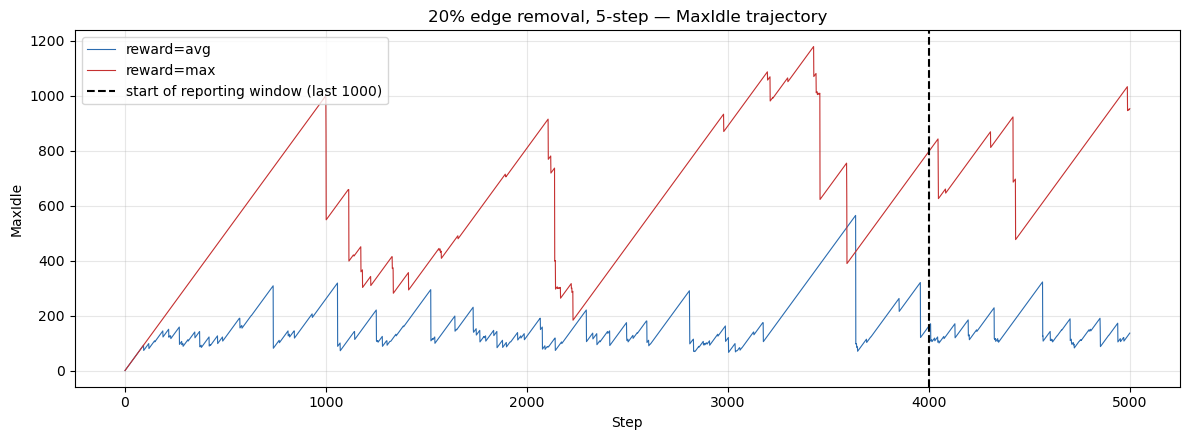

In [43]:
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(max_A, color="#2b6cb0", linewidth=0.8, label="reward=avg")
ax.plot(max_B, color="#c53030", linewidth=0.8, label="reward=max")
ax.axvline(N_STEPS - 1000, color="black", linestyle="--",
           label="start of reporting window (last 1000)")
ax.set_xlabel("Step"); ax.set_ylabel("MaxIdle")
ax.set_title(f"20% edge removal, 5-step — MaxIdle trajectory")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"trajectory_20pct_5step.png", dpi=150); plt.show()

## 15. Baseline — HIF, same graph, same N_STEPS

In [44]:
def run_baseline_hif(n_steps, seed=1, robot1_start=0, robot2_start=99, neighbors=REDUCED_NEIGHBORS):
    sim = CoordinatedHIFSimulator(seed=seed, robot1_pos=robot1_start,
                                  robot2_pos=robot2_start, neighbors_override=neighbors)
    a, m = [], []
    for _ in range(n_steps):
        iai, mx = sim.step(); a.append(iai); m.append(mx)
    return np.array(a), np.array(m)

avg_base, max_base = run_baseline_hif(N_STEPS, seed=1)
report_rollout(f"Baseline HIF (no lookahead), N_STEPS={N_STEPS}", avg_base, max_base);

Baseline HIF (no lookahead), N_STEPS=5000
   mean IAI     : 33.814
   mean MaxIdle : 118.361
   tail slope   : 0.016  (near 0 = healthy, near 1 = collapsing)
   status       : healthy (no permanent abandonment detected)



## 16. Reachability diagnostic — from the main rollout

Reported over the last 1000 steps of the 5000-step reward=max rollout above, i.e. the **same window as the performance table**, so the two are directly comparable. Previously this came from a separate 1000-step run whose window could sit inside a transient and disagree with the main rollout by up to 3x.

DIAGNOSTIC — 5-step, 20% edge removal (reward=max rollout, last 1000 of 5000 steps)
Mean distance to worst node : 5.77
Mean MaxIdle                : 768.71   <- matches the performance table
% steps worst node OUT of 5-step reach (dist > 5) : 61.8%



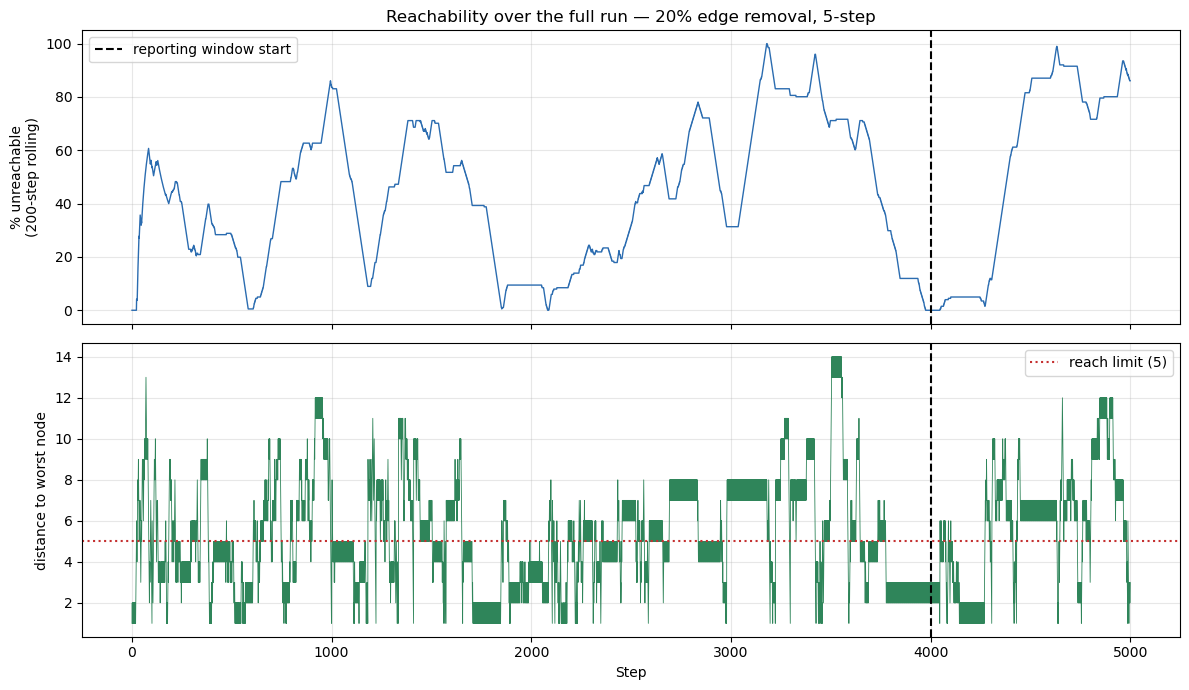

Bounded oscillation inside the reporting window = genuine steady state.
A line pinned at 100% = the abandoned-node case above.


In [45]:
dist_w = dist_B[-1000:]
max_w  = max_B[-1000:]

print("=" * 70)
print(f"DIAGNOSTIC — 5-step, 20% edge removal (reward=max rollout, last 1000 of {N_STEPS} steps)")
print("=" * 70)
print(f"Mean distance to worst node : {dist_w.mean():.2f}")
print(f"Mean MaxIdle                : {max_w.mean():.2f}   <- matches the performance table")
print(f"% steps worst node OUT of 5-step reach (dist > 5) : "
      f"{(dist_w > LOOKAHEAD_DEPTH).mean()*100:.1f}%")
print()
if collapsed_max:
    print("NOTE: the reward=max rollout COLLAPSED. A permanently abandoned node is permanently")
    print("unreachable, so these figures describe the collapse, not normal reachability.")

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
unreach = (dist_B > LOOKAHEAD_DEPTH).astype(float)
win = 200
rolling = np.array([unreach[max(0, i-win):i+1].mean()*100 for i in range(len(unreach))])
axes[0].plot(rolling, color="#2b6cb0", linewidth=1)
axes[0].axvline(N_STEPS - 1000, color="black", linestyle="--", label="reporting window start")
axes[0].set_ylabel("% unreachable\n(200-step rolling)")
axes[0].set_title(f"Reachability over the full run — 20% edge removal, 5-step")
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(dist_B, color="#2f855a", linewidth=0.6)
axes[1].axvline(N_STEPS - 1000, color="black", linestyle="--")
axes[1].axhline(LOOKAHEAD_DEPTH, color="#c53030", linestyle=":", label=f"reach limit (5)")
axes[1].set_ylabel("distance to worst node"); axes[1].set_xlabel("Step")
axes[1].legend(); axes[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"diagnostic_20pct_5step.png", dpi=150); plt.show()

print("Bounded oscillation inside the reporting window = genuine steady state.")
print("A line pinned at 100% = the abandoned-node case above.")

## 17. NO-NN ablation — both reward variants

Prof. Sinha's Jul 16 question: does dropping the network and scoring on instantaneous step values alone change the outcome? Fixed at 5000 steps per variant across all six notebooks.

**Both reward variants are now run.** Earlier notebooks only ever ran reward=max here, which left an asymmetry: the main rollout was compared against reward=avg *and* reward=max, but the ablation only against reward=max. Running both makes the with-NN vs without-NN comparison like-for-like on each variant.

This section passes `build_x=False`, since the ablation never consults the network and therefore does not need the (C, 300) input array — the single largest per-decision cost at depth 5. Both variants together should still be cheaper than the reward=max variant alone was before.

Every run of this ablation so far — full grid, 10% and 20% removal, depths 2/3/5, reward=max — has landed on mean IAI 480.222 / mean MaxIdle 500.500, and 500.5 is exactly the mean of the integers 1..1000. That is the arithmetic fingerprint of one node never being revisited, and it suggests the failure belongs to the no-network policy itself rather than to edge removal. Whether reward=avg does the same here is a genuinely open question — this is the first time it has been measured.

In [46]:
def choose_best_action_NO_NN(idleness, r1_pos, r2_pos, lookahead=LOOKAHEAD_DEPTH,
                             reward_type='max', neighbors=REDUCED_NEIGHBORS):
    """Ablation: cost = instantaneous step values only, no network term."""
    s1 = enumerate_full_paths(r1_pos, lookahead, neighbors)
    s2 = enumerate_full_paths(r2_pos, lookahead, neighbors)
    P1 = seq_positions(r1_pos, s1, lookahead)
    P2 = seq_positions(r2_pos, s2, lookahead)

    # build_x=False: no network consulted, so the (C,300) array is never needed
    valid, _, step_vals, _, _ = eval_candidates(idleness, P1, P2, reward_type, build_x=False)
    if not valid.any():
        m1 = get_valid_moves(r1_pos, neighbors=neighbors)
        m2 = get_valid_moves(r2_pos, neighbors=neighbors)
        return (m1[0][0] if m1 else None), (m2[0][0] if m2 else None)

    costs = np.where(valid, step_vals.max(axis=1), np.inf)
    best = int(np.argmin(costs))
    B = len(s2)
    return s1[best // B][0], s2[best % B][0]

def run_rollout_no_nn(n_steps, reward_type='max', robot1_start=0, robot2_start=99):
    idleness = np.zeros(100, dtype=np.int32)
    r1, r2 = robot1_start, robot2_start
    a, m = [], []
    for _ in range(n_steps):
        d1, d2 = choose_best_action_NO_NN(idleness, r1, r2, reward_type=reward_type)
        q1, q2 = DIRECTIONS[d1](r1), DIRECTIONS[d2](r2)
        idleness += 1
        idleness[q1] = 0; idleness[q2] = 0
        r1, r2 = q1, q2
        a.append(idleness.mean()); m.append(idleness.max())
    return np.array(a), np.array(m)

N_ABLATION_STEPS = 5000

print("NO-NN ablation, reward=avg ...")
avg_nn_A, max_nn_A = run_rollout_no_nn(N_ABLATION_STEPS, reward_type='avg')
print("NO-NN ablation, reward=max ...")
avg_nn_B, max_nn_B = run_rollout_no_nn(N_ABLATION_STEPS, reward_type='max')

print("\n" + "=" * 70)
print(f"NO-NN ABLATION — both variants, N={N_ABLATION_STEPS}")
print("=" * 70)
collapsed_abl_A, _ = report_rollout("NO-NN ablation, reward=avg", avg_nn_A, max_nn_A)
collapsed_abl_B, _ = report_rollout("NO-NN ablation, reward=max", avg_nn_B, max_nn_B)

print("How to read this against Section 14:")
print("  compare reward=avg with-NN vs reward=avg no-NN, and likewise for reward=max.")
print("  If a variant is healthy with the network and collapses without it, the network is")
print("  what prevents that failure for that variant specifically.")
print(f"  (pure-collapse value is {N_ABLATION_STEPS - (1000-1)/2:.1f}, same as the main rollout)")

NO-NN ablation, reward=avg ...
NO-NN ablation, reward=max ...

NO-NN ABLATION — both variants, N=5000
NO-NN ablation, reward=avg
   mean IAI     : 30.682
   mean MaxIdle : 114.739
   tail slope   : -0.016  (near 0 = healthy, near 1 = collapsing)
   status       : healthy (no permanent abandonment detected)

NO-NN ablation, reward=max
   mean IAI     : 4320.220
   mean MaxIdle : 4500.500
   tail slope   : 0.999  (near 0 = healthy, near 1 = collapsing)
   *** COLLAPSED — one node permanently abandoned. ***
   The MaxIdle figure is an artefact of run length, not a performance measure.
   (pure-collapse value for N=5000 is 4500.5; this run is at 100.0%)

How to read this against Section 14:
  compare reward=avg with-NN vs reward=avg no-NN, and likewise for reward=max.
  If a variant is healthy with the network and collapses without it, the network is
  what prevents that failure for that variant specifically.
  (pure-collapse value is 4500.5, same as the main rollout)


## 18. Summary

In [47]:
print("=" * 76)
print(f"SUMMARY — 20% EDGE REMOVAL, 5-STEP LOOKAHEAD")
print("=" * 76)
print(f"N_STEPS {N_STEPS} (report last 1000) | ablation 5000/variant | "
      f"diagnostic merged into rollout | torch seed {TORCH_SEED}")
print()
print(f"{'Policy':<34} {'mean IAI':>12} {'mean MaxIdle':>14}  status")
print("-" * 76)

def _row(label, a, m, n_rep=1000):
    coll, info = detect_collapse(m, n_report=n_rep)
    a = np.asarray(a, dtype=float)
    print(f"{label:<34} {a[-min(n_rep,len(a)):].mean():>12.3f} "
          f"{info['observed_mean']:>14.3f}  {'COLLAPSED' if coll else 'healthy'}")

_row("Baseline HIF (no lookahead)", avg_base, max_base)
print()
_row("Rollout      - reward=avg",   avg_A,    max_A)
_row("NO-NN ablat. - reward=avg",   avg_nn_A, max_nn_A)
print()
_row("Rollout      - reward=max",   avg_B,    max_B)
_row("NO-NN ablat. - reward=max",   avg_nn_B, max_nn_B)
print("-" * 76)
print(f"Diagnostic (same window): mean dist to worst node {dist_w.mean():.2f} | "
      f"% unreachable {(dist_w > LOOKAHEAD_DEPTH).mean()*100:.1f}%")
print()
print("Rows are paired so each reward variant sits directly above its own no-network control.")
print("Any COLLAPSED row has a MaxIdle that is an artefact of run length")
print(f"(pure collapse reads {N_STEPS - (1000-1)/2:.1f}), not a performance measure.")

SUMMARY — 20% EDGE REMOVAL, 5-STEP LOOKAHEAD
N_STEPS 5000 (report last 1000) | ablation 5000/variant | diagnostic merged into rollout | torch seed 0

Policy                                 mean IAI   mean MaxIdle  status
----------------------------------------------------------------------------
Baseline HIF (no lookahead)              33.814        118.361  healthy

Rollout      - reward=avg                36.877        155.104  healthy
NO-NN ablat. - reward=avg                30.682        114.739  healthy

Rollout      - reward=max               209.043        768.705  healthy
NO-NN ablat. - reward=max              4320.220       4500.500  COLLAPSED
----------------------------------------------------------------------------
Diagnostic (same window): mean dist to worst node 5.77 | % unreachable 61.8%

Rows are paired so each reward variant sits directly above its own no-network control.
Any COLLAPSED row has a MaxIdle that is an artefact of run length
(pure collapse reads 4500.5), 

In [48]:
def choose_best_action_instrumented(idleness, r1_pos, r2_pos, lookahead, reward_type, neighbors):
    s1 = enumerate_full_paths(r1_pos, lookahead, neighbors)
    s2 = enumerate_full_paths(r2_pos, lookahead, neighbors)
    P1 = seq_positions(r1_pos, s1, lookahead); P2 = seq_positions(r2_pos, s2, lookahead)
    valid, X, step_vals, _, _ = eval_candidates(idleness, P1, P2, reward_type)
    idx = np.flatnonzero(valid)
    Xv = X[idx].copy(); Xv[:, :100] = (Xv[:, :100] - idle_mean) / idle_std
    with torch.no_grad():
        pred = model(torch.from_numpy(Xv).to(DEVICE)).cpu().numpy()
    pred = pred * y_std + y_mean
    col = 0 if reward_type == 'avg' else 1
    costs = np.maximum(pred[:, col], step_vals[idx].max(axis=1))
    n_tied = int((costs == costs.min()).sum())
    return n_tied, len(costs)

In [49]:
# ↓↓↓ EDIT THESE TWO LINES FOR EACH NOTEBOOK ↓↓↓
GRAPH_NAME = "20pct"              # change to "0pct", "10pct", or "20pct" to match this notebook
NEIGHBOR_VAR = REDUCED_NEIGHBORS  # use NEIGHBORS if this is a 0pct notebook, REDUCED_NEIGHBORS otherwise
# ↑↑↑ EDIT THESE TWO LINES FOR EACH NOTEBOOK ↑↑↑

idleness = np.zeros(100, dtype=np.int32)
r1, r2 = 0, 99
tie_log = []
avg_hist, max_hist, dist_hist = [], [], []

for t in range(5000):
    n_tied, n_total = choose_best_action_instrumented(idleness, r1, r2, LOOKAHEAD_DEPTH, 'max', NEIGHBOR_VAR)
    tie_log.append((n_tied, n_total))
    d1, d2 = choose_best_action_n_step(idleness, r1, r2, LOOKAHEAD_DEPTH, 'max')
    q1, q2 = DIRECTIONS[d1](r1), DIRECTIONS[d2](r2)
    idleness += 1; idleness[q1] = 0; idleness[q2] = 0
    r1, r2 = q1, q2
    avg_hist.append(idleness.mean()); max_hist.append(idleness.max())
    dist_hist.append(0)  # placeholder, not used for this figure

import json
json.dump(tie_log, open(f"tie_log_{GRAPH_NAME}_{LOOKAHEAD_DEPTH}step_max.json", "w"))
np.savez_compressed(f"rollout_{GRAPH_NAME}_{LOOKAHEAD_DEPTH}step_max_RERUN.npz",
                    avg_history=np.array(avg_hist), max_history=np.array(max_hist))

print(f"Done: {GRAPH_NAME}, {LOOKAHEAD_DEPTH}-step")
print("Last-1000 mean avg idleness:", np.array(avg_hist)[-1000:].mean())
print("Last-1000 mean max idleness:", np.array(max_hist)[-1000:].mean())

Done: 20pct, 5-step
Last-1000 mean avg idleness: 209.04324
Last-1000 mean max idleness: 768.705


In [50]:
STARTS = [(0, 99), (10, 88), (33, 70), (5, 95), (50, 51)]
results = {}

for r1s, r2s in STARTS:
    a_b, m_b = run_baseline_hif(5000, seed=1, robot1_start=r1s, robot2_start=r2s)
    a_na, m_na = run_rollout_no_nn(5000, reward_type='avg', robot1_start=r1s, robot2_start=r2s)
    a_nm, m_nm = run_rollout_no_nn(5000, reward_type='max', robot1_start=r1s, robot2_start=r2s)
    results[f"{r1s}_{r2s}"] = dict(
        baseline=[float(a_b[-1000:].mean()), float(m_b[-1000:].mean())],
        nonn_avg=[float(a_na[-1000:].mean()), float(m_na[-1000:].mean())],
        nonn_max=[float(a_nm[-1000:].mean()), float(m_nm[-1000:].mean())],
    )

import json
json.dump(results, open(f"fivestart_{GRAPH_NAME}_{LOOKAHEAD_DEPTH}step.json", "w"), indent=1)
print(json.dumps(results, indent=1))

{
 "0_99": {
  "baseline": [
   33.814240000000005,
   118.361
  ],
  "nonn_avg": [
   30.68198,
   114.739
  ],
  "nonn_max": [
   4320.22,
   4500.5
  ]
 },
 "10_88": {
  "baseline": [
   32.60754,
   109.653
  ],
  "nonn_avg": [
   30.240080000000003,
   108.55
  ],
  "nonn_max": [
   4320.29,
   4500.5
  ]
 },
 "33_70": {
  "baseline": [
   33.79967,
   111.525
  ],
  "nonn_avg": [
   30.031650000000003,
   104.166
  ],
  "nonn_max": [
   4320.49,
   4500.5
  ]
 },
 "5_95": {
  "baseline": [
   34.183350000000004,
   120.451
  ],
  "nonn_avg": [
   30.463369999999998,
   118.6
  ],
  "nonn_max": [
   4320.5,
   4500.5
  ]
 },
 "50_51": {
  "baseline": [
   33.49761,
   112.963
  ],
  "nonn_avg": [
   30.28437,
   112.135
  ],
  "nonn_max": [
   4320.5,
   4500.5
  ]
 }
}


In [52]:
STARTS = [(0, 99), (10, 88), (33, 70), (5, 95), (50, 51)]
results_bl = {}

for seed in [0, 1, 2, 3, 4]:
    for r1s, r2s in STARTS:
        a_b, m_b = run_baseline_hif(5000, seed=seed, robot1_start=r1s, robot2_start=r2s)
        results_bl[f"s{seed}_{r1s}_{r2s}"] = [float(a_b[-1000:].mean()), float(m_b[-1000:].mean())]

import json
print(json.dumps(results_bl, indent=1))

{
 "s0_0_99": [
  33.46182,
  110.766
 ],
 "s0_10_88": [
  33.79153,
  118.2
 ],
 "s0_33_70": [
  33.0196,
  107.457
 ],
 "s0_5_95": [
  33.91747,
  120.6
 ],
 "s0_50_51": [
  33.83513000000001,
  115.616
 ],
 "s1_0_99": [
  33.814240000000005,
  118.361
 ],
 "s1_10_88": [
  32.60754,
  109.653
 ],
 "s1_33_70": [
  33.79967,
  111.525
 ],
 "s1_5_95": [
  34.183350000000004,
  120.451
 ],
 "s1_50_51": [
  33.49761,
  112.963
 ],
 "s2_0_99": [
  33.85168,
  112.769
 ],
 "s2_10_88": [
  33.326130000000006,
  105.328
 ],
 "s2_33_70": [
  32.66552,
  112.186
 ],
 "s2_5_95": [
  33.438629999999996,
  112.914
 ],
 "s2_50_51": [
  34.86098,
  112.289
 ],
 "s3_0_99": [
  34.07606,
  120.417
 ],
 "s3_10_88": [
  34.526089999999996,
  117.408
 ],
 "s3_33_70": [
  33.34609,
  105.957
 ],
 "s3_5_95": [
  33.62683,
  112.129
 ],
 "s3_50_51": [
  33.45718,
  110.287
 ],
 "s4_0_99": [
  33.6156,
  114.126
 ],
 "s4_10_88": [
  32.88457,
  109.667
 ],
 "s4_33_70": [
  34.27149,
  107.52
 ],
 "s4_5_95": 